In [1]:
from google.colab import drive
drive.mount("/content/drive")

Mounted at /content/drive


In [2]:
!pip -q install onnx onnxruntime

import os, json, time, random, shutil, warnings, glob
from concurrent.futures import ThreadPoolExecutor
import numpy as np, pandas as pd, cv2, matplotlib.pyplot as plt, yaml
from scipy.optimize import linear_sum_assignment
from tqdm.auto import tqdm
import onnxruntime as ort
from onnxruntime.quantization import quantize_static, CalibrationDataReader, QuantFormat, QuantType

warnings.filterwarnings('ignore')
SEED = 42
random.seed(SEED)
np.random.seed(SEED)

BASE_DIR = "/content/drive/MyDrive/lane detection"
DATA_DIR = f"{BASE_DIR}/data"
PROCESSED_DIR = f"{DATA_DIR}/processed"
LOCAL_PROCESSED = "/content/processed"
MODELS_DIR = f"{BASE_DIR}/models"
RESULTS_DIR = f"{BASE_DIR}/results"
FIGURES_DIR = f"{RESULTS_DIR}/figures"
PREDICTIONS_DIR = f"{BASE_DIR}/predictions"
STATS_DIR = f"{RESULTS_DIR}/test_stats"
RESULTS_TEST_CSV = f"{RESULTS_DIR}/results_test.csv"
CONDITIONS_CSV = f"{RESULTS_DIR}/results_test_conditions.csv"
EFFICIENCY_CSV = f"{RESULTS_DIR}/efficiency.csv"
for d in [LOCAL_PROCESSED, FIGURES_DIR, STATS_DIR]:
	os.makedirs(d, exist_ok=True)

W, H = 640, 224
DS = {'culane': {'w': 1640, 'h': 590, 'crop': 236}, 'bdd': {'w': 1280, 'h': 720, 'crop': 302}}
LINE_WIDTH = {'culane': 30, 'bdd': 23}
SPLIT_DS = {'val': 'culane', 'test_culane': 'culane', 'test_bdd': 'bdd'}
N_ROWS, N_CELLS = 36, 120
ROWS = np.linspace(10, H - 1, N_ROWS).astype(int)
X_MIN, X_MAX = -0.25 * W, 1.25 * W
CELL = (X_MAX - X_MIN) / N_CELLS
CELLS = np.arange(N_CELLS)
MIN_ROWS = 4
MEAN = np.array([0.485, 0.456, 0.406], np.float32)
STD = np.array([0.229, 0.224, 0.225], np.float32)

CPU_NAME = 'cpu'
for line in open('/proc/cpuinfo'):
	if 'model name' in line:
		CPU_NAME = line.split(':')[1].strip()
		break
THREADS = os.cpu_count()
print(CPU_NAME, '|', THREADS, 'threads')

AMD EPYC 7B12 | 2 threads


In [3]:
def load(name):
	src = f"{PROCESSED_DIR}/{name}"
	dst = f"{LOCAL_PROCESSED}/{name}"
	complete = os.path.exists(f"{dst}/meta.csv") and os.path.exists(f"{dst}/images.npy")
	if complete:
		complete = os.path.getsize(f"{dst}/images.npy") == os.path.getsize(f"{src}/images.npy")
	if not complete:
		shutil.copytree(src, dst, dirs_exist_ok=True)
	images = np.load(f"{dst}/images.npy", mmap_mode='r')
	lanes = np.load(f"{dst}/lanes.npy")
	meta = pd.read_csv(f"{dst}/meta.csv")
	return images, lanes, meta

def resample(x, y):
	order = np.argsort(y)
	x = x[order]
	y = y[order]
	rows = np.arange(H)
	out = np.full(H, np.nan, np.float32)
	inside = (rows >= y[0]) & (rows <= y[-1])
	out[inside] = np.interp(rows[inside], y, x)
	return out

def to_orig(lanes, ds):
	c = DS[ds]
	x = lanes * c['w'] / W
	y = np.arange(H) * (c['h'] - c['crop']) / H + c['crop']
	return x, y

def draw(img, lanes, colors=((0, 255, 0), (255, 0, 0)), thickness=2):
	img = np.array(img)
	for k in range(2):
		rows = np.where(np.isfinite(lanes[k]))[0]
		if len(rows) > 1:
			points = np.stack([lanes[k][rows], rows], 1).round().astype(np.int32)
			cv2.polylines(img, [points], False, colors[k], thickness)
	return img

def lane_mask(x, ds):
	c = DS[ds]
	xo, yo = to_orig(x, ds)
	mask = np.zeros((c['h'] - c['crop'], c['w']), np.uint8)
	rows = np.where(np.isfinite(xo))[0]
	if len(rows) > 1:
		points = np.stack([xo[rows], yo[rows] - c['crop']], 1).round().astype(np.int32)
		cv2.polylines(mask, [points], False, 1, LINE_WIDTH[ds])
	return mask

def iou(a, b):
	union = np.count_nonzero(a | b)
	if union == 0:
		return 0.0
	return np.count_nonzero(a & b) / union

def frame_ious(pred, gt, ds):
	pred_masks = []
	gt_masks = []
	for k in range(2):
		if np.isfinite(pred[k]).sum() > 1:
			pred_masks.append(lane_mask(pred[k], ds))
		else:
			pred_masks.append(None)
		if np.isfinite(gt[k]).sum() > 1:
			gt_masks.append(lane_mask(gt[k], ds))
		else:
			gt_masks.append(None)
	side = []
	for k in range(2):
		if pred_masks[k] is not None and gt_masks[k] is not None:
			side.append(iou(pred_masks[k], gt_masks[k]))
		else:
			side.append(np.nan)
	P = [m for m in pred_masks if m is not None]
	G = [m for m in gt_masks if m is not None]
	matched = []
	if len(P) > 0 and len(G) > 0:
		M = np.zeros((len(P), len(G)))
		for a in range(len(P)):
			for b in range(len(G)):
				M[a, b] = iou(P[a], G[b])
		r, c = linear_sum_assignment(-M)
		matched = list(M[r, c])
	return {'n_pred': len(P), 'n_gt': len(G), 'matched': matched, 'side': side,
	        'pred_on': [m is not None for m in pred_masks], 'gt_on': [m is not None for m in gt_masks]}

def prf(tp, fp, fn):
	if tp + fp + fn == 0:
		return np.nan, np.nan, np.nan
	p = tp / (tp + fp) if tp + fp > 0 else 0.0
	r = tp / (tp + fn) if tp + fn > 0 else 0.0
	f1 = 2 * p * r / (p + r) if p + r > 0 else 0.0
	return p, r, f1

def frame_stats(records):
	rows = []
	for r in records:
		rows.append([sum(m > 0.5 for m in r['matched']), sum(m > 0.7 for m in r['matched']), r['n_pred'], r['n_gt'],
		             int(r['side'][0] > 0.5), int(r['side'][1] > 0.5), int(r['pred_on'][0]), int(r['pred_on'][1]),
		             int(r['gt_on'][0]), int(r['gt_on'][1])])
	return np.array(rows, dtype=np.int64)

def scores_from(stats):
	s = stats.sum(0)
	out = {'frames': len(stats), 'fp': int(s[2] - s[0])}
	if s[3] == 0:
		out.update({'precision': np.nan, 'recall': np.nan, 'f1': np.nan, 'f1@0.7': np.nan, 'f1_left': np.nan, 'f1_right': np.nan})
		return out
	p, r, f1 = prf(s[0], s[2] - s[0], s[3] - s[0])
	out['precision'] = p
	out['recall'] = r
	out['f1'] = f1
	out['f1@0.7'] = prf(s[1], s[2] - s[1], s[3] - s[1])[2]
	out['f1_left'] = prf(s[4], s[6] - s[4], s[8] - s[4])[2]
	out['f1_right'] = prf(s[5], s[7] - s[5], s[9] - s[5])[2]
	return out

def bootstrap_f1(stats, clips, n=1000):
	ids, inverse = np.unique(clips, return_inverse=True)
	per_clip = np.zeros((len(ids), stats.shape[1]))
	np.add.at(per_clip, inverse, stats)
	rng = np.random.default_rng(SEED)
	values = []
	for _ in range(n):
		s = per_clip[rng.integers(0, len(ids), len(ids))].sum(0)
		values.append(prf(s[0], s[2] - s[0], s[3] - s[0])[2])
	low, high = np.nanpercentile(values, [2.5, 97.5])
	return low, high

In [4]:
GT = {}
for split in ['test_culane', 'test_bdd']:
	GT[split] = (np.load(f"{PROCESSED_DIR}/{split}/lanes.npy"), pd.read_csv(f"{PROCESSED_DIR}/{split}/meta.csv"))

RUNS = []
for folder in sorted(os.listdir(PREDICTIONS_DIR)):
	if 'quick' in folder:
		continue
	if os.path.exists(f"{PREDICTIONS_DIR}/{folder}/test_culane.npz") and os.path.exists(f"{PREDICTIONS_DIR}/{folder}/test_bdd.npz"):
		RUNS.append(folder)

tables = []
for name in ['results.csv', 'results_dino.csv', 'results_yolo.csv', 'results_best.csv']:
	path = f"{RESULTS_DIR}/{name}"
	if os.path.exists(path):
		tables.append(pd.read_csv(path))
VAL = pd.concat(tables, ignore_index=True).drop_duplicates('run', keep='last').set_index('run')
print(len(RUNS), 'models to test:')
print(RUNS)

17 models to test:
['baseline', 'dino_finetune_dinov3_vits16', 'dino_finetune_smooth', 'dino_frozen_dinov3_vits16', 'dino_frozen_resnet18', 'ensemble_final', 'ensemble_r18_dino_flip_smooth', 'ensemble_resnet_dino_flip', 'plain_resnet18_l3', 'r18_640x224_smooth', 'resnet34_v2_fulldata', 'rowanchor_r18_384x128', 'rowanchor_r18_512x192', 'rowanchor_r18_640x224', 'student_r18_384x128_v2', 'student_resnet18_l3', 'yolo26n_seg']


In [5]:
def run_stats(run, split):
	path = f"{STATS_DIR}/{run}_{split}.npy"
	if os.path.exists(path):
		return np.load(path)
	pred = np.load(f"{PREDICTIONS_DIR}/{run}/{split}.npz")['lanes']
	gt, meta = GT[split]
	with ThreadPoolExecutor(8) as pool:
		records = list(pool.map(frame_ious, pred, gt, [SPLIT_DS[split]] * len(gt)))
	stats = frame_stats(records)
	np.save(path, stats)
	return stats

STATS = {}
for run in tqdm(RUNS, desc='scoring'):
	for split in ['test_culane', 'test_bdd']:
		STATS[(run, split)] = run_stats(run, split)
print('done')

scoring:   0%|          | 0/17 [00:00<?, ?it/s]

done


In [6]:
rows = []
for run in RUNS:
	row = {'run': run}
	if run in VAL.index:
		row['val_f1'] = VAL.loc[run, 'f1']
		row['params'] = VAL.loc[run, 'params']
		row['gflops'] = VAL.loc[run, 'gflops'] if 'gflops' in VAL.columns else np.nan
		row['gpu_ms'] = VAL.loc[run, 'ms_per_frame']
	for split, short in [('test_culane', 'culane'), ('test_bdd', 'bdd')]:
		stats = STATS[(run, split)]
		s = scores_from(stats)
		low, high = bootstrap_f1(stats, GT[split][1].clip_id.values)
		row[f'{short}_f1'] = s['f1']
		row[f'{short}_ci_low'] = low
		row[f'{short}_ci_high'] = high
		row[f'{short}_precision'] = s['precision']
		row[f'{short}_recall'] = s['recall']
		row[f'{short}_f1@0.7'] = s['f1@0.7']
		row[f'{short}_f1_left'] = s['f1_left']
		row[f'{short}_f1_right'] = s['f1_right']
	rows.append(row)
TEST = pd.DataFrame(rows).sort_values('culane_f1', ascending=False)
TEST.to_csv(RESULTS_TEST_CSV, index=False)
columns = ['run', 'val_f1', 'culane_f1', 'culane_ci_low', 'culane_ci_high', 'culane_f1@0.7', 'culane_precision', 'culane_recall',
           'bdd_f1', 'bdd_ci_low', 'bdd_ci_high', 'params', 'gflops', 'gpu_ms']
display(TEST[columns].round(4))

,run,val_f1,culane_f1,culane_ci_low,culane_ci_high,culane_f1@0.7,culane_precision,culane_recall,bdd_f1,bdd_ci_low,bdd_ci_high,params,gflops,gpu_ms
5,ensemble_final,0.7796,0.6930,0.6578,0.7222,0.5367,0.6827,0.7037,0.1686,0.1562,0.1806,57226559,123.91,44.29
7,ensemble_resnet_dino_flip,0.7797,0.6909,0.6554,0.7190,0.5361,0.6817,0.7004,0.1643,0.1522,0.1757,34879434,81.70,30.78
6,ensemble_r18_dino_flip_smooth,0.7801,0.6906,0.6546,0.7189,0.5355,0.6814,0.7001,0.1740,0.1621,0.1854,34879434,81.70,30.48
2,dino_finetune_smooth,0.7532,0.6782,0.6440,0.7082,0.5189,0.6674,0.6895,0.1610,0.1492,0.1715,22622037,30.38,11.67
1,dino_finetune_dinov3_vits16,0.7520,0.6773,0.6429,0.7077,0.5178,0.6665,0.6886,0.1513,0.1396,0.1617,22622037,30.38,11.86
16,yolo26n_seg,0.7329,0.6628,0.6311,0.6898,0.4689,0.7779,0.5773,0.1606,0.1464,0.1744,3083302,10.42,35.93
10,resnet34_v2_fulldata,0.7527,0.6568,0.6247,0.6844,0.4956,0.6422,0.6721,0.1476,0.1367,0.1586,22347125,21.10,5.75
9,r18_640x224_smooth,0.7546,0.6559,0.6253,0.6828,0.4995,0.6427,0.6696,0.1434,0.1321,0.1546,12257397,10.47,3.18
13,rowanchor_r18_640x224,0.7526,0.6510,0.6208,0.6767,0.4927,0.6379,0.6646,0.1300,0.1197,0.1406,12257397,10.47,3.41
12,rowanchor_r18_512x192,0.7417,0.6387,0.6091,0.6642,0.4706,0.6300,0.6475,0.1494,0.1383,0.1612,12071541,7.19,3.13


test_culane : F1 per condition


condition,arrow,cross,crowd,curve,hlight,night,noline,normal,shadow
run,,,,,,,,,
ensemble_final,0.855,NaN,0.757,0.675,0.623,0.688,0.467,0.898,0.688
ensemble_resnet_dino_flip,0.845,NaN,0.753,0.684,0.617,0.685,0.460,0.902,0.693
ensemble_r18_dino_flip_smooth,0.848,NaN,0.754,0.680,0.617,0.685,0.458,0.901,0.693
dino_finetune_smooth,0.832,NaN,0.741,0.650,0.607,0.685,0.442,0.888,0.693
dino_finetune_dinov3_vits16,0.832,NaN,0.742,0.650,0.605,0.681,0.438,0.889,0.693
yolo26n_seg,0.758,NaN,0.729,0.594,0.536,0.705,0.444,0.836,0.681
resnet34_v2_fulldata,0.814,NaN,0.723,0.627,0.597,0.646,0.436,0.882,0.652
r18_640x224_smooth,0.823,NaN,0.712,0.627,0.604,0.660,0.437,0.876,0.648
rowanchor_r18_640x224,0.820,NaN,0.710,0.617,0.599,0.652,0.431,0.874,0.645


Crossroad (no lines): false positives out of 422 frames


,cross_fp
run,
ensemble_final,273
ensemble_resnet_dino_flip,286
ensemble_r18_dino_flip_smooth,286
dino_finetune_smooth,289
dino_finetune_dinov3_vits16,289
yolo26n_seg,102
resnet34_v2_fulldata,330
r18_640x224_smooth,383
rowanchor_r18_640x224,383


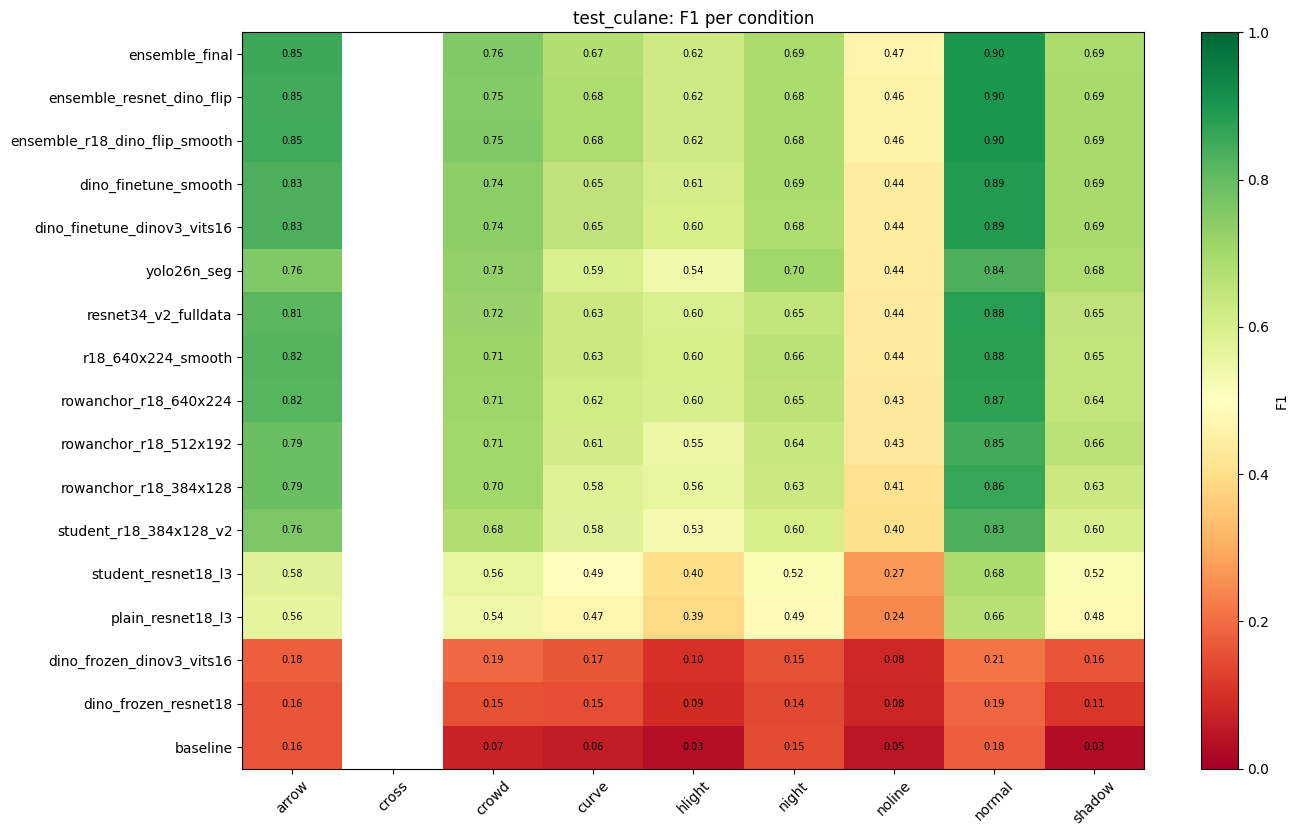

test_bdd : F1 per condition


condition,bad_weather,dawn_dusk,day_city,day_highway,night
run,,,,,
ensemble_final,0.121,0.195,0.135,0.194,0.192
ensemble_resnet_dino_flip,0.112,0.191,0.138,0.193,0.182
ensemble_r18_dino_flip_smooth,0.116,0.199,0.147,0.204,0.197
dino_finetune_smooth,0.119,0.183,0.129,0.186,0.182
dino_finetune_dinov3_vits16,0.111,0.168,0.122,0.175,0.175
yolo26n_seg,0.115,0.179,0.112,0.185,0.196
resnet34_v2_fulldata,0.097,0.166,0.127,0.175,0.167
r18_640x224_smooth,0.100,0.165,0.112,0.151,0.185
rowanchor_r18_640x224,0.087,0.155,0.102,0.137,0.165


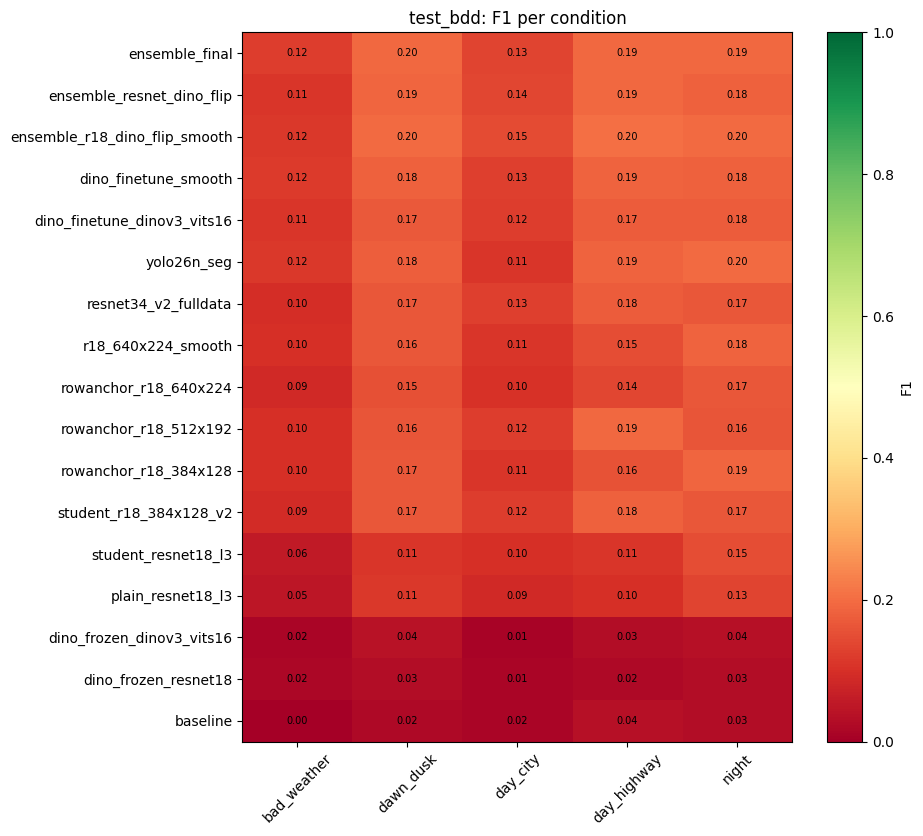

In [7]:
condition_rows = []
for run in RUNS:
	for split in ['test_culane', 'test_bdd']:
		stats = STATS[(run, split)]
		meta = GT[split][1]
		for condition in sorted(meta.condition.unique()):
			s = scores_from(stats[meta.condition.values == condition])
			condition_rows.append({'run': run, 'split': split, 'condition': condition, **s})
CONDITIONS = pd.DataFrame(condition_rows)
CONDITIONS.to_csv(CONDITIONS_CSV, index=False)

for split in ['test_culane', 'test_bdd']:
	table = CONDITIONS[CONDITIONS.split == split].pivot(index='run', columns='condition', values='f1')
	table = table.loc[TEST.run]
	print(split, ': F1 per condition')
	display(table.round(3))
	if split == 'test_culane':
		fp = CONDITIONS[(CONDITIONS.split == split) & (CONDITIONS.condition == 'cross')].set_index('run').loc[TEST.run, 'fp']
		print('Crossroad (no lines): false positives out of', int(CONDITIONS[(CONDITIONS.condition == 'cross')].frames.iloc[0]), 'frames')
		display(fp.to_frame('cross_fp'))
	plt.figure(figsize=(1.1 * table.shape[1] + 4, 0.38 * table.shape[0] + 2))
	plt.imshow(table.values, cmap='RdYlGn', vmin=0, vmax=1, aspect='auto')
	plt.colorbar(label='F1')
	plt.xticks(range(table.shape[1]), table.columns, rotation=45)
	plt.yticks(range(table.shape[0]), table.index)
	for i in range(table.shape[0]):
		for j in range(table.shape[1]):
			if np.isfinite(table.values[i, j]):
				plt.text(j, i, f"{table.values[i, j]:.2f}", ha='center', va='center', fontsize=7)
	plt.title(f'{split}: F1 per condition')
	plt.tight_layout()
	plt.savefig(f"{FIGURES_DIR}/conditions_{split}.png", dpi=120)
	plt.show()

In [8]:
def open_session(path):
	options = ort.SessionOptions()
	options.intra_op_num_threads = THREADS
	return ort.InferenceSession(path, options, providers=['CPUExecutionProvider'])

def input_size(session):
	shape = session.get_inputs()[0].shape
	return int(shape[3]), int(shape[2])

def to_input(img, size):
	img = np.asarray(img)
	if size != (W, H):
		img = cv2.resize(img, size, interpolation=cv2.INTER_AREA)
	x = (img / 255.0 - MEAN) / STD
	return x.transpose(2, 0, 1)[None].astype(np.float32)

def latency(session, runs=100):
	name = session.get_inputs()[0].name
	w, h = input_size(session)
	x = np.random.rand(1, 3, h, w).astype(np.float32)
	for _ in range(10):
		session.run(None, {name: x})
	start = time.time()
	for _ in range(runs):
		session.run(None, {name: x})
	return (time.time() - start) / runs * 1000

def smooth_lanes(lanes, sigma, degree):
	out = np.full_like(lanes, np.nan)
	for i in range(len(lanes)):
		for k in range(2):
			rows = np.where(np.isfinite(lanes[i, k]))[0]
			if len(rows) > degree + 2:
				weights = 1 / (np.nan_to_num(sigma[i, k, rows], nan=5.0) + 1)
				coef = np.polyfit(rows, lanes[i, k, rows], degree, w=weights)
				top, bottom = rows.min(), rows.max()
				out[i, k, top:bottom + 1] = np.polyval(coef, np.arange(top, bottom + 1))
	return out

def to_lanes(mean, spread, prob, threshold, smooth):
	xs = X_MIN + (mean + 0.5) * CELL
	sig = spread * CELL
	n = len(mean)
	lanes = np.full((n, 2, H), np.nan, np.float32)
	sigma = np.full((n, 2, H), np.nan, np.float32)
	for i in range(n):
		for k in range(2):
			on = prob[i, k] > threshold
			if on.sum() >= MIN_ROWS:
				lanes[i, k] = resample(xs[i, k, on], ROWS[on])
				sigma[i, k] = resample(sig[i, k, on], ROWS[on])
	if smooth is not None:
		lanes = smooth_lanes(lanes, sigma, smooth)
	return lanes

def decode_one(position, exist):
	p = np.exp(position - position.max(-1, keepdims=True))
	p = p / p.sum(-1, keepdims=True)
	mean = (p * CELLS).sum(-1)
	spread = np.sqrt((p * (CELLS - mean[..., None]) ** 2).sum(-1))
	prob = 1 / (1 + np.exp(-exist))
	return mean[0], spread[0], prob[0]

def onnx_test_f1(session, threshold, smooth):
	images, _, _ = load('test_culane')
	name = session.get_inputs()[0].name
	size = input_size(session)
	means, spreads, probs = [], [], []
	for i in tqdm(range(len(images)), leave=False, desc='int8 test'):
		position, exist = session.run(None, {name: to_input(images[i], size)})[:2]
		m, s, p = decode_one(position, exist)
		means.append(m)
		spreads.append(s)
		probs.append(p)
	lanes = to_lanes(np.stack(means), np.stack(spreads), np.stack(probs), threshold, smooth)
	gt, meta = GT['test_culane']
	with ThreadPoolExecutor(8) as pool:
		records = list(pool.map(frame_ious, lanes, gt, ['culane'] * len(gt)))
	return scores_from(frame_stats(records))['f1']

class Calibration(CalibrationDataReader):
	def __init__(self, name, size):
		images, _, _ = load('val')
		self.items = iter([{name: to_input(images[i], size)} for i in range(0, 6400, 100)])

	def get_next(self):
		return next(self.items, None)

done = pd.read_csv(EFFICIENCY_CSV) if os.path.exists(EFFICIENCY_CSV) else pd.DataFrame(columns=['run'])
for path in sorted(glob.glob(f"{MODELS_DIR}/*/model.onnx")):
	run = path.split('/')[-2]
	if run in done.run.values or 'quick' in run:
		continue
	session = open_session(path)
	row_anchor = 'position' in [o.name for o in session.get_outputs()]
	row = {'run': run, 'cpu': CPU_NAME, 'threads': THREADS, 'input': '%dx%d' % input_size(session), 'fp32_ms': latency(session)}
	if row_anchor:
		int8_path = path.replace('model.onnx', 'model_int8.onnx')
		try:
			quantize_static(path, int8_path, Calibration(session.get_inputs()[0].name, input_size(session)),
			                quant_format=QuantFormat.QDQ, per_channel=True, weight_type=QuantType.QInt8, activation_type=QuantType.QUInt8)
			int8 = open_session(int8_path)
			config = yaml.safe_load(open(f"{MODELS_DIR}/{run}/config.yaml"))
			row['int8_ms'] = latency(int8)
			row['int8_test_culane_f1'] = onnx_test_f1(int8, config['threshold'], config.get('smooth'))
		except Exception as e:
			print(run, 'INT8 failed:', type(e).__name__, e)
	print(row)
	done = pd.concat([done, pd.DataFrame([row])], ignore_index=True)
	done.to_csv(EFFICIENCY_CSV, index=False)

frame = (np.random.rand(590, 1640, 3) * 255).astype(np.uint8)
start = time.time()
for _ in range(200):
	img = cv2.cvtColor(cv2.resize(frame[236:], (W, H), interpolation=cv2.INTER_AREA), cv2.COLOR_BGR2RGB)
	x = to_input(img, (W, H))
pre_ms = (time.time() - start) / 200 * 1000
position = np.random.randn(1, 2, N_ROWS, N_CELLS).astype(np.float32)
exist = np.random.randn(1, 2, N_ROWS).astype(np.float32) + 2
start = time.time()
for _ in range(200):
	m, s, p = decode_one(position, exist)
	to_lanes(m[None], s[None], p[None], 0.4, 3)
post_ms = (time.time() - start) / 200 * 1000

EFFICIENCY = pd.read_csv(EFFICIENCY_CSV)
EFFICIENCY = EFFICIENCY.merge(TEST[['run', 'culane_f1', 'gflops', 'params', 'gpu_ms']], on='run', how='left')
EFFICIENCY.to_csv(EFFICIENCY_CSV, index=False)
print(f'pre-processing {pre_ms:.2f} ms | post-processing (decode + smoothing) {post_ms:.2f} ms | on {CPU_NAME}, {THREADS} threads')
display(EFFICIENCY.round(3))

int8 test:   0%|          | 0/3798 [00:00<?, ?it/s]

{'run': 'dino_frozen_resnet18', 'cpu': 'AMD EPYC 7B12', 'threads': 2, 'input': '640x224', 'fp32_ms': 126.20378971099855, 'int8_ms': 67.90554523468018, 'int8_test_culane_f1': np.float64(0.12098138747884941)}


int8 test:   0%|          | 0/3798 [00:00<?, ?it/s]

{'run': 'plain_resnet18_l3', 'cpu': 'AMD EPYC 7B12', 'threads': 2, 'input': '640x224', 'fp32_ms': 103.18623304367065, 'int8_ms': 52.26612091064453, 'int8_test_culane_f1': np.float64(0.4619391323759209)}


int8 test:   0%|          | 0/3798 [00:00<?, ?it/s]

{'run': 'r18_640x224_smooth', 'cpu': 'AMD EPYC 7B12', 'threads': 2, 'input': '640x224', 'fp32_ms': 121.06932401657104, 'int8_ms': 64.7539472579956, 'int8_test_culane_f1': np.float64(0.6513829315190061)}


... (9 outputs left out)

{'run': 'student_r18_384x128_v2', 'cpu': 'AMD EPYC 7B12', 'threads': 2, 'input': '640x224', 'fp32_ms': 40.628743171691895, 'int8_ms': 23.72758388519287, 'int8_test_culane_f1': np.float64(0.5912274235164025)}


int8 test:   0%|          | 0/3798 [00:00<?, ?it/s]

{'run': 'student_resnet18_l3', 'cpu': 'AMD EPYC 7B12', 'threads': 2, 'input': '640x224', 'fp32_ms': 102.16556310653687, 'int8_ms': 63.47338199615478, 'int8_test_culane_f1': np.float64(0.4716730598996754)}
{'run': 'yolo26n_seg', 'cpu': 'AMD EPYC 7B12', 'threads': 2, 'input': '640x224', 'fp32_ms': 48.18589687347412}
pre-processing 9.51 ms | post-processing (decode + smoothing) 0.88 ms | on AMD EPYC 7B12, 2 threads


,run,cpu,threads,input,fp32_ms,int8_ms,int8_test_culane_f1,culane_f1,gflops,params,gpu_ms
0,dino_frozen_resnet18,AMD EPYC 7B12,2.0,640x224,126.204,67.906,0.121,0.127,10.53,12238965,3.42
1,plain_resnet18_l3,AMD EPYC 7B12,2.0,640x224,103.186,52.266,0.462,0.466,8.17,12189717,2.64
2,r18_640x224_smooth,AMD EPYC 7B12,2.0,640x224,121.069,64.754,0.651,0.656,10.47,12257397,3.18
3,resnet34_v2_fulldata,AMD EPYC 7B12,2.0,640x224,255.379,136.082,0.646,0.657,21.10,22347125,5.75
4,rowanchor_r18_384x128,AMD EPYC 7B12,2.0,384x128,44.521,23.797,0.627,0.634,3.61,11885685,3.25
5,rowanchor_r18_512x192,AMD EPYC 7B12,2.0,512x192,87.382,57.616,0.637,0.639,7.19,12071541,3.13
6,rowanchor_r18_640x224,AMD EPYC 7B12,2.0,640x224,129.608,63.514,0.645,0.651,10.47,12257397,3.41
7,student_r18_384x128_v2,AMD EPYC 7B12,2.0,640x224,40.629,23.728,0.591,0.607,3.63,11867253,3.73
8,student_resnet18_l3,AMD EPYC 7B12,2.0,640x224,102.166,63.473,0.472,0.487,8.17,12189717,2.65
9,yolo26n_seg,AMD EPYC 7B12,2.0,640x224,48.186,NaN,NaN,0.663,10.42,3083302,35.93


CPU ms = 12.40 * GFLOPs + -0.72, R² = 1.000


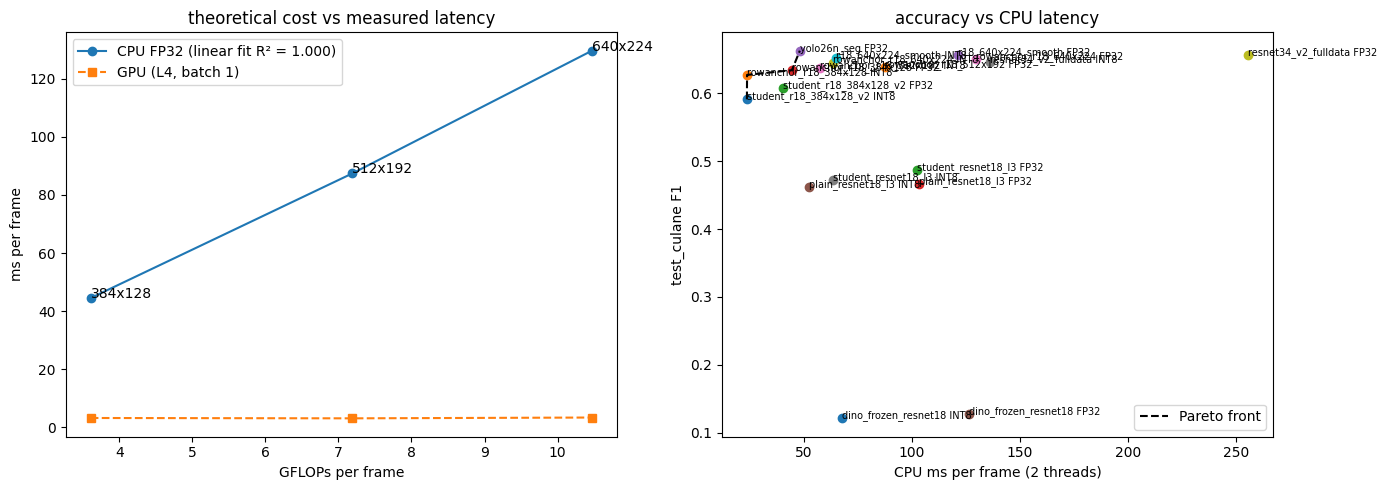

In [9]:
sweep = EFFICIENCY[EFFICIENCY.run.isin(['rowanchor_r18_384x128', 'rowanchor_r18_512x192', 'rowanchor_r18_640x224'])].sort_values('gflops')
plt.figure(figsize=(14, 5))
plt.subplot(1, 2, 1)
if len(sweep) >= 2:
	slope, intercept = np.polyfit(sweep.gflops, sweep.fp32_ms, 1)
	predicted = slope * sweep.gflops + intercept
	r2 = 1 - ((sweep.fp32_ms - predicted) ** 2).sum() / ((sweep.fp32_ms - sweep.fp32_ms.mean()) ** 2).sum()
	plt.plot(sweep.gflops, sweep.fp32_ms, 'o-', label=f'CPU FP32 (linear fit R² = {r2:.3f})')
	plt.plot(sweep.gflops, sweep.gpu_ms, 's--', label='GPU (L4, batch 1)')
	for _, r in sweep.iterrows():
		plt.annotate(r.input, (r.gflops, r.fp32_ms))
	print(f'CPU ms = {slope:.2f} * GFLOPs + {intercept:.2f}, R² = {r2:.3f}')
plt.xlabel('GFLOPs per frame')
plt.ylabel('ms per frame')
plt.title('theoretical cost vs measured latency')
plt.legend()

plt.subplot(1, 2, 2)
points = []
for _, r in EFFICIENCY.iterrows():
	if np.isfinite(r.culane_f1):
		points.append((r.fp32_ms, r.culane_f1, r.run + ' FP32'))
	if 'int8_ms' in EFFICIENCY.columns and np.isfinite(r.get('int8_ms', np.nan)) and np.isfinite(r.get('int8_test_culane_f1', np.nan)):
		points.append((r.int8_ms, r.int8_test_culane_f1, r.run + ' INT8'))
points = sorted(points)
front = []
best = -1
for ms, f1, label in points:
	if f1 > best:
		front.append((ms, f1))
		best = f1
for ms, f1, label in points:
	plt.scatter(ms, f1)
	plt.annotate(label, (ms, f1), fontsize=7)
if front:
	plt.plot([p[0] for p in front], [p[1] for p in front], 'k--', label='Pareto front')
plt.xlabel(f'CPU ms per frame ({THREADS} threads)')
plt.ylabel('test_culane F1')
plt.title('accuracy vs CPU latency')
plt.legend()
plt.tight_layout()
plt.savefig(f"{FIGURES_DIR}/efficiency.png", dpi=120)
plt.show()

best model: ensemble_final | weakest condition: noline


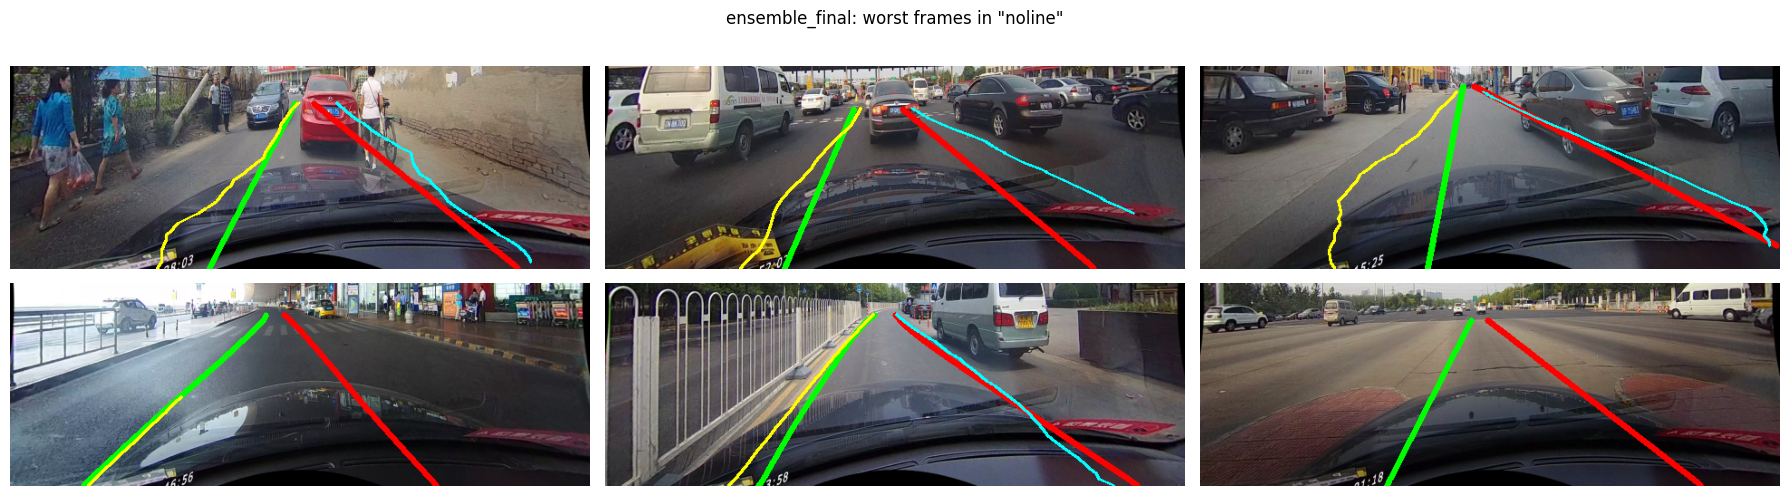

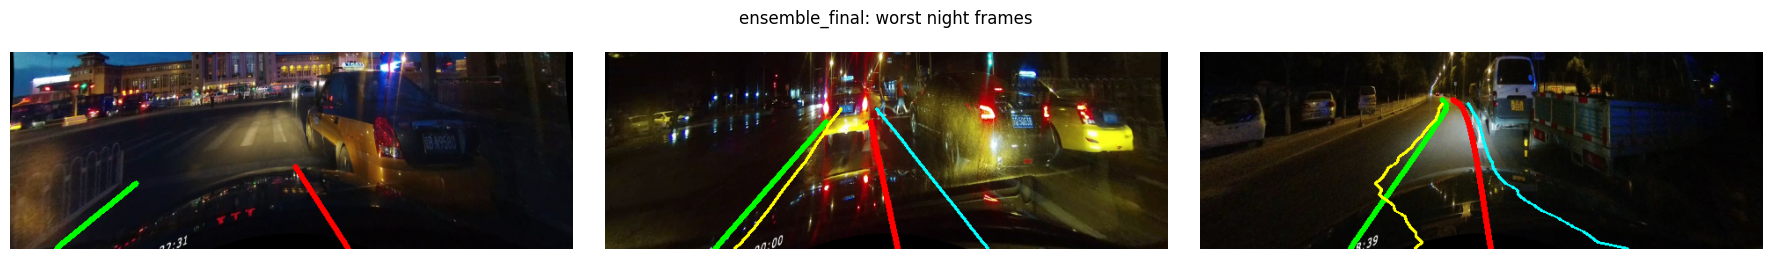

In [10]:
best_run = TEST.iloc[0].run
stats = STATS[(best_run, 'test_culane')]
images, gt_lanes, meta = load('test_culane')
pred = np.load(f"{PREDICTIONS_DIR}/{best_run}/test_culane.npz")['lanes']
per_condition = CONDITIONS[(CONDITIONS.run == best_run) & (CONDITIONS.split == 'test_culane')].dropna(subset=['f1'])
weakest = per_condition.sort_values('f1').iloc[0].condition
frame_score = stats[:, 0] / np.maximum(np.maximum(stats[:, 2], stats[:, 3]), 1)
has_gt = stats[:, 3] > 0

def gallery(condition, count, title, path):
	idx = np.where((meta.condition.values == condition) & has_gt)[0]
	idx = idx[np.argsort(frame_score[idx])][:count]
	n_rows = (len(idx) + 2) // 3
	plt.figure(figsize=(18, 2.6 * n_rows))
	for j, i in enumerate(idx):
		img = draw(images[i], gt_lanes[i], thickness=6)
		img = draw(img, pred[i], colors=((255, 255, 0), (0, 255, 255)))
		plt.subplot(n_rows, 3, j + 1)
		plt.imshow(img)
		plt.axis('off')
	plt.suptitle(title)
	plt.tight_layout()
	plt.savefig(path, dpi=120, bbox_inches='tight')
	plt.show()

print('best model:', best_run, '| weakest condition:', weakest)
gallery(weakest, 6, f'{best_run}: worst frames in "{weakest}"', f"{FIGURES_DIR}/failures_{weakest}.png")
gallery('night', 3, f'{best_run}: worst night frames', f"{FIGURES_DIR}/failures_night.png")

In [11]:
summary = TEST[['run', 'val_f1', 'culane_f1', 'culane_ci_low', 'culane_ci_high', 'bdd_f1', 'params', 'gflops', 'gpu_ms']].copy()
summary = summary.merge(EFFICIENCY[['run', 'fp32_ms'] + [c for c in ['int8_ms', 'int8_test_culane_f1'] if c in EFFICIENCY.columns]], on='run', how='left')
display(summary.round(4))
summary.to_csv(f"{RESULTS_DIR}/summary_for_report.csv", index=False)

if os.path.exists(f"{RESULTS_DIR}/results_tracking.csv"):
	tracking = pd.read_csv(f"{RESULTS_DIR}/results_tracking.csv")
	print('tracker results (notebook 5):')
	display(tracking[tracking.tracker.isin(['none', 'simple', 'kalman_basic', 'kalman_full'])].round(3))

,run,val_f1,culane_f1,culane_ci_low,culane_ci_high,bdd_f1,params,gflops,gpu_ms,fp32_ms,int8_ms,int8_test_culane_f1
0,ensemble_final,0.7796,0.6930,0.6578,0.7222,0.1686,57226559,123.91,44.29,NaN,NaN,NaN
1,ensemble_resnet_dino_flip,0.7797,0.6909,0.6554,0.7190,0.1643,34879434,81.70,30.78,NaN,NaN,NaN
2,ensemble_r18_dino_flip_smooth,0.7801,0.6906,0.6546,0.7189,0.1740,34879434,81.70,30.48,NaN,NaN,NaN
3,dino_finetune_smooth,0.7532,0.6782,0.6440,0.7082,0.1610,22622037,30.38,11.67,NaN,NaN,NaN
4,dino_finetune_dinov3_vits16,0.7520,0.6773,0.6429,0.7077,0.1513,22622037,30.38,11.86,NaN,NaN,NaN
5,yolo26n_seg,0.7329,0.6628,0.6311,0.6898,0.1606,3083302,10.42,35.93,48.1859,NaN,NaN
6,resnet34_v2_fulldata,0.7527,0.6568,0.6247,0.6844,0.1476,22347125,21.10,5.75,255.3788,136.0819,0.6465
7,r18_640x224_smooth,0.7546,0.6559,0.6253,0.6828,0.1434,12257397,10.47,3.18,121.0693,64.7539,0.6514
8,rowanchor_r18_640x224,0.7526,0.6510,0.6208,0.6767,0.1300,12257397,10.47,3.41,129.6081,63.5143,0.6453
9,rowanchor_r18_512x192,0.7417,0.6387,0.6091,0.6642,0.1494,12071541,7.19,3.13,87.3819,57.6161,0.6369


tracker results (notebook 5):


,tracker,data,f1,f1_left,f1_right,jitter,wrong_swaps_per_1000,both_lines_pct,coasted_pct,ms_per_frame_cpu,videos
0,none,synthetic_test,0.860,0.849,0.853,10.367,12.667,61.867,0.000,0.002,NaN
1,none,culane_test_videos,NaN,NaN,NaN,1.398,0.000,100.000,0.000,0.002,1.0
2,simple,synthetic_test,0.796,0.793,0.797,4.690,5.333,86.213,13.750,0.622,NaN
3,simple,culane_test_videos,NaN,NaN,NaN,1.025,0.000,100.000,0.093,0.622,1.0
4,kalman_basic,synthetic_test,0.743,0.739,0.746,5.226,0.733,99.633,20.680,0.911,NaN
5,kalman_basic,culane_test_videos,NaN,NaN,NaN,1.029,0.000,100.000,0.093,0.911,1.0
6,kalman_full,synthetic_test,0.974,0.971,0.976,1.821,0.000,97.767,6.553,0.878,NaN
7,kalman_full,culane_test_videos,NaN,NaN,NaN,0.791,0.000,99.741,0.574,0.878,1.0


In [12]:
drive.flush_and_unmount()
from google.colab import runtime
runtime.unassign()